In [1]:
from structured_optics import *
from structured_optics.hologram import slm_hologram
import numpy as np
import matplotlib.pyplot as plt

In [2]:
pixel_size = 8e-6
mu = 7/5
beam = Beam(nix = pixel_size*640/2, Dx = 640,
            niy = pixel_size*480/2, Dy = 480,
            waist = mu*0.5e-3, lamb = 633e-9)

k = beam.k()

In [3]:
def calculate_fix_std_LG(p, l):
    N = 2*p + abs(l) + 1
    A = C**2 / N                       # target w(z)^2
    disc = 1 - 16*z**2/(k**2 * A**2)
    if disc < 0:
        print(f"mode ({p},{l}) impossible: need A >= 4z/k")
        return None
    W2 = (A/2)*(1 + np.sqrt(disc))     # waist^2 at the SLM image plane
    W = np.sqrt(W2)
    return W/mu                  # waist on the SLM

def calculate_fix_std_HG(n):
    N = 2*n + 1
    A = C**2 / N                       # target w(z)^2
    disc = 1 - 16*z**2/(k**2 * A**2)
    if disc < 0:
        print(f"mode ({n},{0}) impossible: need A >= 4z/k")
        return None
    W2 = (A/2)*(1 + np.sqrt(disc))     # waist^2 at the SLM image plane
    W = np.sqrt(W2)
    return W/mu 

In [9]:
#For fixed std

hg_modes = [[0,0], [0,1], [1,0], [2,0], [1,1], [0,2], [3,0], [2,1], [1,2], [0,3], [4,0], [3,1], [2,2], [1,3], [0,4], [5,0], [4,1], [3,2], [2,3], [1,4], [0,5]]
lg_modes = [[0,0], [0,1], [0,-1], [0,2], [1,0], [0,-2], [0,3], [1,1], [1,-1], [0,-3], [0,4], [1, 2], [1,-2], [2, 0], [0,-4], [0,5], [1,3], [1, -3], [2, 1], [2,-1], [0,-5]]

C = 1.1e-3
z = 30e-2


In [10]:
std_lg = []
for mode in range(len(lg_modes)):

    n = lg_modes[mode][0]   
    m = lg_modes[mode][1]

    #beam.waist = np.sqrt(2*C**2/(2*n + np.abs(m) +1) + 2*np.sqrt(np.abs(C**4/(2*n + np.abs(m) +1)**2 - z**2/beam.k()**2)))/mu
    beam.waist = calculate_fix_std_LG(n, m)*mu
    print(beam.waist)
    beam.lg(l=m, p=n)
    beam.propagate(z)
    std_lg.append(beam.std()[0])
    """plt.figure()
    plt.pcolormesh(beam.x, beam.y, beam.int_profile())
    plt.title(f"l={m}, p={n}")"""


0.0010986231014478562
0.000773885691078865
0.000773885691078865
0.0006277428218927924
0.0006277428218927924
0.0006277428218927924
0.0005384199226900848
0.0005384199226900848
0.0005384199226900848
0.0005384199226900848
0.00047520482765857206
0.00047520482765857206
0.00047520482765857206
0.00047520482765857206
0.00047520482765857206
0.00042607474381535986
0.00042607474381535986
0.00042607474381535986
0.00042607474381535986
0.00042607474381535986
0.00042607474381535986


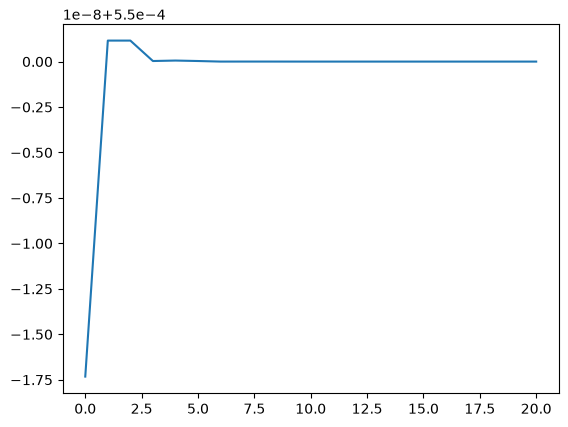

In [11]:
plt.plot(np.array(std_lg))


In [12]:
std_hg = []

for n in range(5):
    beam.waist = mu*calculate_fix_std_HG(n)
    print(beam.waist)
    beam.hg(n=n, m=0)
    beam.propagate(z)

    std_hg.append(beam.std()[0])
    """plt.figure()
    plt.pcolormesh(beam.x, beam.y, beam.int_profile())"""


0.0010986231014478562
0.0006277428218927924
0.00047520482765857206
0.00038497113732708515
0.00031085815436951236


0.0005499826754511849 0.0005500000000035946


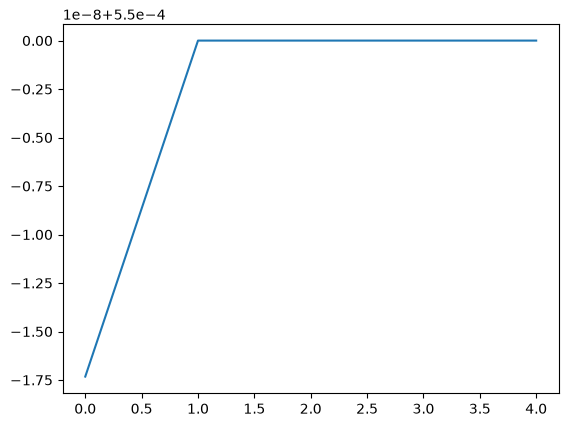

In [ ]:
std_lga = np.array(std_hg)
plt.plot(std_lga)

print(np.min(std_lga), np.max(std_lga))